## Sentiment Analysis using LSTM

In [5]:
import pandas as pd
import numpy as np
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.models import load_model
import re

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [2]:
cd /content/drive/MyDrive/Colab Notebooks/Deep Learning

/content/drive/MyDrive/Colab Notebooks/Deep Learning


In [3]:
data = pd.read_csv('IMDB Dataset.csv')

print(data)

                                                  review sentiment
0      One of the other reviewers has mentioned that ...  positive
1      A wonderful little production. <br /><br />The...  positive
2      I thought this was a wonderful way to spend ti...  positive
3      Basically there's a family where a little boy ...  negative
4      Petter Mattei's "Love in the Time of Money" is...  positive
...                                                  ...       ...
49995  I thought this movie did a down right good job...  positive
49996  Bad plot, bad dialogue, bad acting, idiotic di...  negative
49997  I am a Catholic taught in parochial elementary...  negative
49998  I'm going to have to disagree with the previou...  negative
49999  No one expects the Star Trek movies to be high...  negative

[50000 rows x 2 columns]


In [6]:
english_stops = set(stopwords.words('english'))

In [7]:
def load_dataset():
    df = pd.read_csv('IMDB Dataset.csv')
    x_data = df['review']       # Reviews/Input
    y_data = df['sentiment']    # Sentiment/Output

    # PRE-PROCESS REVIEW
    x_data = x_data.replace({'<.*?>': ''}, regex = True)          # remove html tag
    x_data = x_data.replace({'[^A-Za-z]': ' '}, regex = True)     # remove non alphabet
    x_data = x_data.apply(lambda review: [w for w in review.split() if w not in english_stops])  # remove stop words
    x_data = x_data.apply(lambda review: [w.lower() for w in review])   # lower case

    # ENCODE SENTIMENT -> 0 & 1
    y_data = y_data.replace('positive', 1)
    y_data = y_data.replace('negative', 0)

    return x_data, y_data

x_data, y_data = load_dataset()

print('Reviews')
print(x_data, '\n')
print('Sentiment')
print(y_data)

Reviews
0        [one, reviewers, mentioned, watching, oz, epis...
1        [a, wonderful, little, production, the, filmin...
2        [i, thought, wonderful, way, spend, time, hot,...
3        [basically, family, little, boy, jake, thinks,...
4        [petter, mattei, love, time, money, visually, ...
                               ...                        
49995    [i, thought, movie, right, good, job, it, crea...
49996    [bad, plot, bad, dialogue, bad, acting, idioti...
49997    [i, catholic, taught, parochial, elementary, s...
49998    [i, going, disagree, previous, comment, side, ...
49999    [no, one, expects, star, trek, movies, high, a...
Name: review, Length: 50000, dtype: object 

Sentiment
0        1
1        1
2        1
3        0
4        1
        ..
49995    1
49996    0
49997    0
49998    0
49999    0
Name: sentiment, Length: 50000, dtype: int64


<ipython-input-7-5f078287338f>:14: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_data = y_data.replace('negative', 0)


In [8]:
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size = 0.2)

print('Train Set')
print(x_train, '\n')
print(x_test, '\n')
print('Test Set')
print(y_train, '\n')
print(y_test)

Train Set
26552    [dakota, incident, one, strangest, westerns, i...
14658    [what, happening, itv, drama, first, losing, g...
1652     [i, planned, seeing, movie, however, i, disapp...
9669     [amando, deossorio, never, one, let, lack, bud...
20709    [there, reasons, i, watch, show, i, invested, ...
                               ...                        
43406    [another, turgid, action, adventure, flick, qu...
23902    [but, least, movie, got, deserved, sent, satel...
46496    [i, excited, concept, favorite, comic, book, h...
10940    [edge, city, directed, martin, ritt, stars, jo...
27655    [principally, story, two, men, part, portugues...
Name: review, Length: 40000, dtype: object 

34774    [michelle, anic, e, alvina, nice, i, really, f...
3692     [the, version, the, time, machine, latest, str...
25616    [when, i, flicking, tv, guide, came, across, t...
43826    [i, lived, next, door, author, first, moved, p...
19831    [let, state, right, start, i, not, hate, show,...
 

In [9]:
def get_max_length():
    review_length = []
    for review in x_train:
        review_length.append(len(review))

    return int(np.ceil(np.mean(review_length)))

In [10]:
token = Tokenizer(lower=False)
x_train = token.texts_to_sequences(x_train)
x_test = token.texts_to_sequences(x_test)

max_length = get_max_length()

x_train = pad_sequences(x_train, maxlen=max_length, padding='post', truncating='post')
x_test = pad_sequences(x_test, maxlen=max_length, padding='post', truncating='post')

total_words = len(token.word_index) + 1

print('Encoded X Train\n', x_train, '\n')
print('Encoded X Test\n', x_test, '\n')
print('Maximum review length: ', max_length)

Encoded X Train
 [[ 9363  3064     5 ...   303 12133   177]
 [  106  1369 10010 ...   474   650   323]
 [    1  3858   219 ...     0     0     0]
 ...
 [    1  2213  1060 ...     0     0     0]
 [ 1162   439   424 ...  3225    10   200]
 [18873    13    36 ...     0     0     0]] 

Encoded X Test
 [[ 2840   648 60871 ...  4312   204   172]
 [    2   222     2 ...   268    10  3726]
 [  170     1 29903 ...     0     0     0]
 ...
 [    1  1315  3297 ...     0     0     0]
 [   23     1   812 ...     0     0     0]
 [    9     3   780 ...     0     0     0]] 

Maximum review length:  130


In [11]:
# ARCHITECTURE
EMBED_DIM = 32
LSTM_OUT = 64

model = Sequential()
model.add(Embedding(total_words, EMBED_DIM, input_length = max_length))
model.add(LSTM(LSTM_OUT))
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

print(model.summary())

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [13]:
checkpoint = ModelCheckpoint(
    'models/LSTM.keras',
    monitor='accuracy',
    save_best_only=True,
    verbose=1
)

In [14]:
model.fit(x_train, y_train, batch_size = 128, epochs = 5, callbacks=[checkpoint])

Epoch 1/5
311/313 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5389 - loss: 0.6828
Epoch 1: accuracy improved from -inf to 0.58258, saving model to models/LSTM.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5393 - loss: 0.6826
Epoch 2/5
312/313 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6189 - loss: 0.6405
Epoch 2: accuracy improved from 0.58258 to 0.58455, saving model to models/LSTM.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.6187 - loss: 0.6406
Epoch 3/5
310/313 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5567 - loss: 0.6638
Epoch 3: accuracy did not improve from 0.58455
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.5569 - loss: 0.6638
Epoch 4/5
309/313 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5981 - loss: 0.6585
Epoch 4: accuracy improved from 0.58455 to 0.60745, saving model to models/LSTM.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.5983 - loss: 0.6584
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step -

In [16]:
y_pred_probs = model.predict(x_test, batch_size=128)
y_pred = (y_pred_probs > 0.5).astype(int)

true = 0
for i, y in enumerate(y_test):
    if y == y_pred[i]:
        true += 1

print('Correct Prediction: {}'.format(true))
print('Wrong Prediction: {}'.format(len(y_pred) - true))
print('Accuracy: {}'.format(true/len(y_pred)*100))

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Correct Prediction: 7490
Wrong Prediction: 2510
Accuracy: 74.9


## Image generation using GAN

In [17]:
from __future__ import print_function, division
from keras.datasets import mnist
from keras.layers import Input, Dense, Reshape, Flatten, Dropout
from keras.layers import BatchNormalization, Activation, ZeroPadding2D
from keras.layers import LeakyReLU
from keras.layers import UpSampling2D, Conv2D
from keras.models import Sequential, Model
from keras. optimizers import Adam, SGD
import tensorflow as tf
tf.keras.utils.disable_interactive_logging()

import matplotlib.pyplot as plt
import sys
import numpy as np

num_rows = 28
num_cols = 28
num_channels = 1
input_shape = (num_rows, num_cols, num_channels)
z_size = 100

(train_ims, _), (_, _) = mnist.load_data()
train_ims = train_ims / 127.5 - 1.
train_ims = np.expand_dims(train_ims, axis=3)

batch_size = 32
valid = np.ones((batch_size, 1))
fake = np.zeros((batch_size, 1))


In [18]:
def build_generator():
    gen_model = Sequential()
    gen_model.add(Dense(256, input_dim=z_size))
    gen_model.add(LeakyReLU(alpha=0.2))
    gen_model.add(BatchNormalization(momentum=0.8))
    gen_model.add(Dense(512))
    gen_model.add(LeakyReLU(alpha=0.2))
    gen_model.add(BatchNormalization(momentum=0.8))
    gen_model.add(Dense(1024))
    gen_model.add(LeakyReLU(alpha=0.2))
    gen_model.add(BatchNormalization(momentum=0.8))
    gen_model.add(Dense(np.prod(input_shape), activation='tanh'))
    gen_model.add(Reshape(input_shape))

    gen_noise = Input(shape=(z_size,))
    gen_img = gen_model(gen_noise)
    return Model(gen_noise, gen_img)


In [19]:
def build_discriminator():

	disc_model = Sequential()
	disc_model.add(Flatten(input_shape=input_shape))
	disc_model.add(Dense(512))
	disc_model.add(LeakyReLU(alpha=0.2))
	disc_model.add(Dense(256))
	disc_model.add(LeakyReLU(alpha=0.2))
	disc_model.add(Dense(1, activation='sigmoid'))

	disc_img = Input(shape=input_shape)
	validity = disc_model(disc_img)
	return Model(disc_img, validity)


In [20]:
# discriminator
disc= build_discriminator()
disc.compile(loss='binary_crossentropy',
    optimizer='sgd',
    metrics=['accuracy'])

generator = build_generator()
z = Input(shape=(z_size,))
# generator
img = generator(z)

disc.trainable = False

validity = disc(img)

# combined model
combined = Model(z, validity)
combined.compile(loss='binary_crossentropy', optimizer='sgd')


/usr/local/lib/python3.10/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.10/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [21]:
def intialize_model():
    disc= build_discriminator()
    disc.compile(loss='binary_crossentropy',
        optimizer='sgd',
        metrics=['accuracy'])

    generator = build_generator()

    z = Input(shape=(z_size,))
    img = generator(z)

    disc.trainable = False

    validity = disc(img)

    combined = Model(z, validity)
    combined.compile(loss='binary_crossentropy', optimizer='sgd')
    return disc, generator, combined



In [22]:
def train(epochs, batch_size=128, sample_interval=50):
    # load images
    (train_ims, _), (_, _) = mnist.load_data()
    # preprocess
    train_ims = train_ims / 127.5 - 1.
    train_ims = np.expand_dims(train_ims, axis=3)

    valid = np.ones((batch_size, 1))
    fake = np.zeros((batch_size, 1))
    # training loop
    for epoch in range(epochs):

        batch_index = np.random.randint(0, train_ims.shape[0], batch_size)
        imgs = train_ims[batch_index]
    # create noise
        noise = np.random.normal(0, 1, (batch_size, z_size))
    # predict using a Generator
        gen_imgs = gen.predict(noise)
    # calculate loss functions
        real_disc_loss = disc.train_on_batch(imgs, valid)
        fake_disc_loss = disc.train_on_batch(gen_imgs, fake)
        disc_loss_total = 0.5 * np.add(real_disc_loss, fake_disc_loss)

        noise = np.random.normal(0, 1, (batch_size, z_size))

        g_loss = full_model.train_on_batch(noise, valid)
    # show outputs every few epochs
        if epoch % sample_interval == 0:
            one_batch(epoch)


In [23]:
def one_batch(epoch):
    r, c = 5, 5
    noise = np.random.normal(0, 1, (r * c, z_size))
    gen_imgs = gen.predict(noise)

    # Rescale images 0 - 1
    gen_imgs = 0.5 * gen_imgs + 0.5

    fig, axs = plt.subplots(r, c)
    cnt = 0
    for i in range(r):
        for j in range(c):
            axs[i,j].imshow(gen_imgs[cnt, :,:,0], cmap='gray')
            axs[i,j].axis('off')
            cnt += 1
    plt.show()


/usr/local/lib/python3.10/dist-packages/keras/src/backend/tensorflow/trainer.py:75: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


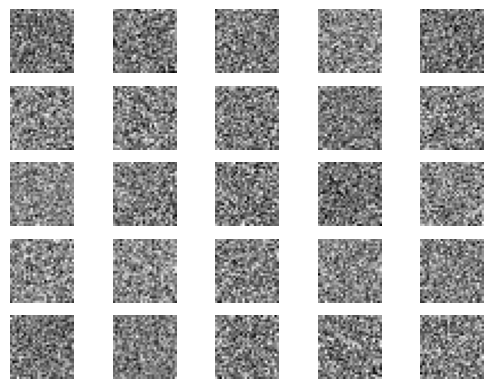

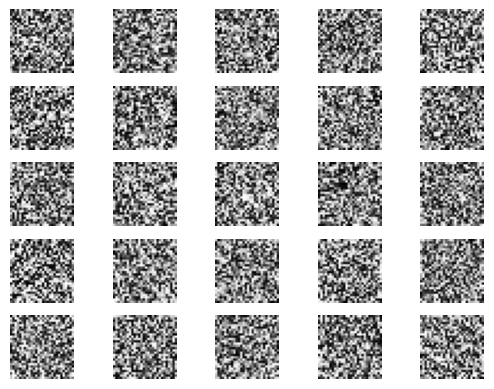

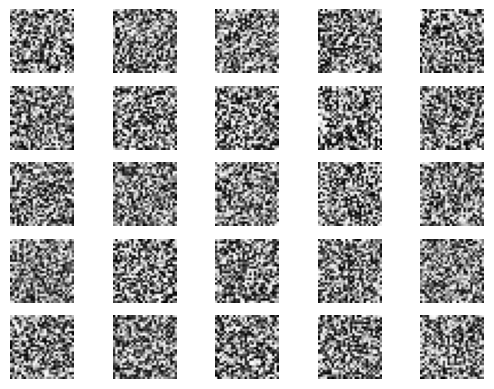

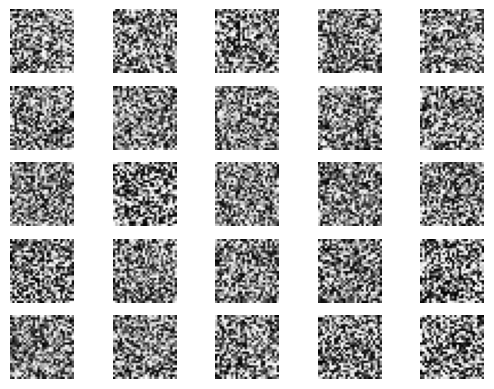

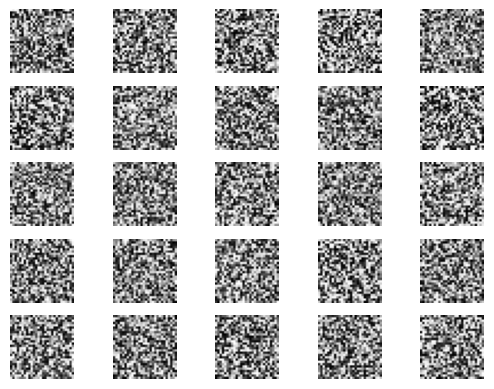

KeyboardInterrupt: 

In [ ]:
disc, gen, full_model = intialize_model()
train(epochs=5000, batch_size=32, sample_interval=200)